<a href="https://colab.research.google.com/github/Angeltt251/Mineria-de-Datos/blob/main/Lab_2_6_Reglas_de_Asociacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Actividad 2.6 — Laboratorio: Implementación de Reglas de Asociación

**Asignatura:** IEI097 Minería de Datos · Unidad II · Semana 08  
**Autor:** José Miguel Flores Chávez · Instituto Profesional Santo Tomás  
**Tipo:** laboratorio individual en Google Colab


**Contenido:** 1. Carga · 2. Preparación · 3. Itemsets frecuentes · 4. Reglas y comparación de umbrales · 5. Interpretación

> El notebook usa el archivo `Association_Algorithm.csv`. Si no está en la carpeta de trabajo de Colab, la celda de carga pide subirlo.

## Fase 1 · Carga del dataset

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlxtend
from mlxtend.frequent_patterns import apriori, association_rules

# Ignorar las advertencias de desactualización (DeprecationWarnings) en la salida
warnings.filterwarnings("ignore", category=DeprecationWarning)

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 20)

print("pandas :", pd.__version__)
print("mlxtend:", mlxtend.__version__)

pandas : 2.2.3
mlxtend: 0.23.4


In [5]:
from google.colab import files
archivos_subidos = files.upload()
nombre_csv = next(iter(archivos_subidos))
print("Archivo seleccionado:", nombre_csv)

Saving Association Algorithm.csv to Association Algorithm (1).csv
Archivo seleccionado: Association Algorithm (1).csv


In [6]:
import pandas as pd
import os

# Ruta directa al archivo ya existente en el entorno
ruta_csv = "/content/Association Algorithm.csv"

if os.path.exists(ruta_csv):
    df_raw = pd.read_csv(ruta_csv)
    print("Archivo cargado correctamente desde el entorno local.")
    display(df_raw.head())
else:
    print(f"No se encontró el archivo en {ruta_csv}. Por favor asegúrate de subirlo.")

Archivo cargado correctamente desde el entorno local.


,Transaction ID,Items
0,1,"bread, milk, eggs"
1,2,"bread, juice, butter"
2,3,"milk, eggs, butter"
3,4,"bread, milk"
4,5,"bread, eggs"


### Descripción del dataset

- **Contexto en una frase:** compras de un almacén de barrio con cinco productos de consumo básico.
- **Transacción:** una compra, identificada por `Transaction ID`.
- **Ítem:** un producto dentro de esa compra. Vienen todos juntos en la columna `Items`, separados por comas.
- **Formato original:** una fila por compra (ítems en una sola celda de texto), no una fila por ítem.

In [7]:
transacciones_lista = df_raw["Items"].str.split(",").apply(lambda xs: [x.strip().lower() for x in xs])
items_distintos = sorted({i for lista in transacciones_lista for i in lista})

resumen = pd.DataFrame({
    "Indicador": ["Transacciones", "Ítems distintos", "Ítems por compra (mínimo)", "Ítems por compra (promedio)", "Ítems por compra (máximo)"],
    "Valor": [len(df_raw), len(items_distintos), transacciones_lista.apply(len).min(),
              round(transacciones_lista.apply(len).mean(), 2), transacciones_lista.apply(len).max()],
})
print("Ítems:", items_distintos)
resumen

Ítems: ['bread', 'butter', 'eggs', 'juice', 'milk']


,Indicador,Valor
0,Transacciones,20.0
1,Ítems distintos,5.0
2,Ítems por compra (mínimo),1.0
3,Ítems por compra (promedio),2.3
4,Ítems por compra (máximo),3.0


## Fase 2 · Preparación de los datos

### Revisión de calidad

In [8]:
print("Nulos por columna:")
print(df_raw.isna().sum(), "\n")
print("Filas duplicadas        :", df_raw.duplicated().sum())
print("IDs de transacción repetidos:", df_raw["Transaction ID"].duplicated().sum())
print("Celdas de Items con espacios sobrantes:", int((df_raw["Items"] != df_raw["Items"].str.strip()).sum()))
print("Nombres con mayúsculas :", sum(i != i.lower() for l in df_raw["Items"].str.split(",") for i in map(str.strip, l)))

Nulos por columna:
Transaction ID    0
Items             0
dtype: int64 

Filas duplicadas        : 0
IDs de transacción repetidos: 0
Celdas de Items con espacios sobrantes: 0
Nombres con mayúsculas : 0


### Limpieza aplicada

1. Se eliminan filas con nulos (no se podría asignar el ítem a una compra).
2. Se separa la columna `Items` por comas y se pasa cada producto a su propia fila.
3. Se normaliza el texto (espacios y minúsculas), para que `Milk` y `milk ` sean el mismo ítem.
4. Se eliminan nombres vacíos o que no son productos (`NO_PRODUCTOS`).
5. Se eliminan ítems repetidos dentro de una misma compra, porque Apriori trabaja con presencia o ausencia, no con cantidades.

In [9]:
NO_PRODUCTOS = {"", "nan", "none", "null", "n/a", "bags", "bolsa"}

df = (df_raw.rename(columns={"Transaction ID": "id_transaccion", "Items": "item"})
            .dropna()
            .assign(item=lambda d: d["item"].str.split(","))
            .explode("item")
            .reset_index(drop=True))
df["item"] = df["item"].str.strip().str.lower()

n_inicial = len(df)
df = df[~df["item"].isin(NO_PRODUCTOS)]
n_sin_no_productos = len(df)
df = df.drop_duplicates(subset=["id_transaccion", "item"]).reset_index(drop=True)

print(f"Filas tras separar los ítems       : {n_inicial}")
print(f"Filas eliminadas por no ser producto: {n_inicial - n_sin_no_productos}")
print(f"Ítems repetidos en una compra       : {n_sin_no_productos - len(df)}")
print(f"Filas finales                       : {len(df)}")
df.head(10)

Filas tras separar los ítems       : 46
Filas eliminadas por no ser producto: 0
Ítems repetidos en una compra       : 0
Filas finales                       : 46


,id_transaccion,item
0,1,bread
1,1,milk
2,1,eggs
3,2,bread
4,2,juice
5,2,butter
6,3,milk
7,3,eggs
8,3,butter
9,4,bread


### Codificación one-hot (tabla transaccional binaria)

Apriori necesita una tabla con **una fila por transacción**, **una columna por ítem** y valores **verdadero/falso** (el ítem estuvo o no en esa compra).

**¿Por qué este formato?** Apriori cuenta en cuántas compras aparece cada combinación de productos. Con una columna booleana por ítem, el soporte de una combinación es la fracción de filas donde todas sus columnas valen `True`. El formato original (ítems como texto separado por comas) no permite hacer ese conteo directamente, y el formato largo repite el identificador de la compra en cada fila.

In [10]:
basket = pd.crosstab(df["id_transaccion"], df["item"]).astype(bool)
basket.columns.name = None
N = len(basket)

print(f"Tabla codificada: {basket.shape[0]} transacciones x {basket.shape[1]} ítems")
basket

Tabla codificada: 20 transacciones x 5 ítems


,bread,butter,eggs,juice,milk
id_transaccion,,,,,
1,True,False,True,False,True
2,True,True,False,True,False
3,False,True,True,False,True
4,True,False,False,False,True
5,True,False,True,False,False
6,False,True,False,True,False
7,True,False,True,False,True
8,True,False,False,True,False
9,False,True,False,False,True


## Fase 3 · Itemsets frecuentes

### Distribución de frecuencias

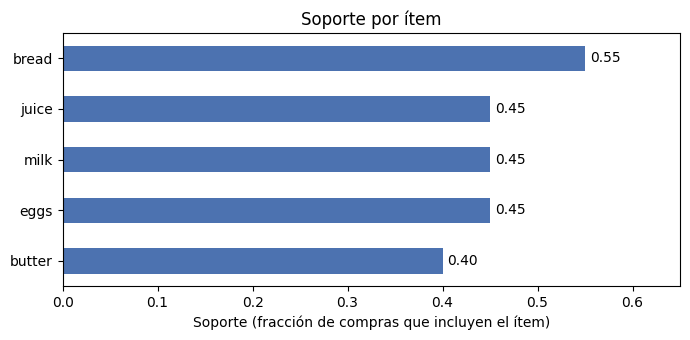

,compras,soporte
bread,11,0.55
eggs,9,0.45
juice,9,0.45
milk,9,0.45
butter,8,0.40


In [11]:
soporte_items = basket.mean().sort_values(ascending=False)
frecuencias = pd.DataFrame({"compras": basket.sum().reindex(soporte_items.index), "soporte": soporte_items})

fig, ax = plt.subplots(figsize=(7, 3.5))
soporte_items.sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_xlabel("Soporte (fracción de compras que incluyen el ítem)")
ax.set_title("Soporte por ítem")
for i, v in enumerate(soporte_items.sort_values()):
    ax.text(v + 0.005, i, f"{v:.2f}", va="center")
ax.set_xlim(0, 0.65)
plt.tight_layout()
plt.show()

frecuencias

In [12]:
cortes = [0.50, 0.40, 0.30, 0.25, 0.20, 0.15, 0.10, 0.05]

tabla_cortes = pd.DataFrame({
    "soporte mínimo": cortes,
    "compras mínimas": [int(round(s * N)) for s in cortes],
    "itemsets frecuentes": [len(apriori(basket, min_support=s, use_colnames=True)) for s in cortes],
})

print("Combinaciones posibles con 5 ítems:", 2 ** basket.shape[1] - 1)
tabla_cortes

Combinaciones posibles con 5 ítems: 31


,soporte mínimo,compras mínimas,itemsets frecuentes
0,0.50,10,1
1,0.40,8,5
2,0.30,6,5
3,0.25,5,8
4,0.20,4,9
5,0.15,3,13
6,0.10,2,17
7,0.05,1,22


### Soporte mínimo elegido: 0.10

- Cada compra pesa 1/20 = 0.05 del total. Con **0.05** basta una sola compra para que una combinación sea «frecuente»: eso es una anécdota, no un patrón.
- Con **0.10** se exigen al menos **2 compras**, el mínimo posible para hablar de repetición.
- Desde 0.15 hacia arriba se pierden 4 combinaciones que sí se repiten en 2 compras (ver tabla anterior: de 17 a 13 itemsets).

Con solo 5 productos hay 31 combinaciones posibles, así que aquí no hay riesgo de agotar la memoria; en un dataset grande este mismo criterio se aplicaría bajando el soporte de forma gradual.

In [13]:
SOP_BASE = 0.10
CONF_BASE = 0.30

frecuentes = apriori(basket, min_support=SOP_BASE, use_colnames=True)
frecuentes["tamaño"] = frecuentes["itemsets"].apply(len)
frecuentes["itemset"] = frecuentes["itemsets"].apply(lambda s: " + ".join(sorted(s)))
frecuentes["compras"] = (frecuentes["support"] * N).round().astype(int)
frecuentes = frecuentes.sort_values(["tamaño", "support", "itemset"], ascending=[True, False, True]).reset_index(drop=True)

print(f"Itemsets frecuentes con soporte >= {SOP_BASE}: {len(frecuentes)}")
print(frecuentes["tamaño"].value_counts().sort_index().rename("itemsets por tamaño").to_string())
frecuentes[["itemset", "tamaño", "compras", "support"]]

Itemsets frecuentes con soporte >= 0.1: 17
tamaño
1     5
2    10
3     2


,itemset,tamaño,compras,support
0,bread,1,11,0.55
1,eggs,1,9,0.45
2,juice,1,9,0.45
3,milk,1,9,0.45
4,butter,1,8,0.40
5,bread + eggs,2,5,0.25
6,bread + juice,2,5,0.25
7,bread + milk,2,5,0.25
8,bread + butter,2,4,0.20
9,butter + eggs,2,3,0.15


## Fase 4 · Reglas de asociación

### Cómo leer las métricas

Para una regla **A → B**:

| Métrica | Qué mide | Fórmula |
|---|---|---|
| **Soporte** | Qué tan frecuente es A+B en todas las compras | `P(A y B)` |
| **Confianza** | De las compras con A, qué fracción también tiene B | `P(A y B) / P(A)` |
| **Lift** | Cuántas veces más seguido aparece B junto a A que en una compra cualquiera | `confianza / P(B)` |

Lift > 1: asociación positiva. Lift ≈ 1: independientes. Lift < 1: se compran juntos menos de lo esperable.

**Criterio de orden:** por **lift** (de mayor a menor) y, a igual lift, por confianza. La confianza sola engaña cuando el consecuente es un producto muy común (aquí el pan está en el 55 % de las compras).

**Confianza mínima base = 0.30.** Las canastas tienen entre 1 y 3 productos, así que las confianzas son moderadas por naturaleza. Dejo el umbral bajo y uso el lift como filtro de calidad.

In [14]:
def generar_reglas(itemsets, min_conf, n_trans):
    if (itemsets["itemsets"].apply(len) >= 2).sum() == 0:
        return pd.DataFrame()
    try:
        r = association_rules(itemsets, metric="confidence", min_threshold=min_conf, num_itemsets=n_trans)
    except TypeError:
        r = association_rules(itemsets, metric="confidence", min_threshold=min_conf)
    if len(r) == 0:
        return r
    r["antecedente"] = r["antecedents"].apply(lambda s: " + ".join(sorted(s)))
    r["consecuente"] = r["consequents"].apply(lambda s: " + ".join(sorted(s)))
    r["compras"] = (r["support"] * n_trans).round().astype(int)
    r["compras_antecedente"] = (r["antecedent support"] * n_trans).round().astype(int)
    r = (r.assign(_l=r["lift"].round(4), _c=r["confidence"].round(4))
          .sort_values(["_l", "_c", "antecedente"], ascending=[False, False, True])
          .drop(columns=["_l", "_c"])
          .reset_index(drop=True))
    return r


COLS_VISTA = ["antecedente", "consecuente", "compras", "support", "confidence", "lift"]

reglas = generar_reglas(frecuentes[["support", "itemsets"]], CONF_BASE, N)

print(f"Reglas con soporte >= {SOP_BASE} y confianza >= {CONF_BASE}: {len(reglas)}")
print(f"Lift > 1: {(reglas['lift'] > 1.0000001).sum()} | lift = 1: {((reglas['lift'] - 1).abs() < 1e-9).sum()} | lift < 1: {(reglas['lift'] < 0.9999999).sum()}")
reglas[COLS_VISTA].round(3)

Reglas con soporte >= 0.1 y confianza >= 0.3: 22
Lift > 1: 9 | lift = 1: 1 | lift < 1: 12


,antecedente,consecuente,compras,support,confidence,lift
0,butter + juice,bread,2,0.10,0.667,1.212
1,eggs + milk,bread,2,0.10,0.667,1.212
2,bread + butter,juice,2,0.10,0.500,1.111
3,eggs,bread,5,0.25,0.556,1.010
4,juice,bread,5,0.25,0.556,1.010
5,milk,bread,5,0.25,0.556,1.010
6,bread,eggs,5,0.25,0.455,1.010
7,bread,juice,5,0.25,0.455,1.010
8,bread,milk,5,0.25,0.455,1.010
9,bread + juice,butter,2,0.10,0.400,1.000


### Experimento: comparación de cuatro configuraciones de umbrales

De la más estricta a la más permisiva.

In [15]:
CONFIGS = [
    {"config": "A · estricta",         "min_support": 0.25, "min_conf": 0.50},
    {"config": "B · intermedia",       "min_support": 0.15, "min_conf": 0.40},
    {"config": "C · base",             "min_support": 0.10, "min_conf": 0.30},
    {"config": "D · muy permisiva",    "min_support": 0.05, "min_conf": 0.10},
]

resultados = []
for cfg in CONFIGS:
    t0 = time.time()
    its = apriori(basket, min_support=cfg["min_support"], use_colnames=True)
    rg = generar_reglas(its, cfg["min_conf"], N)
    n_reglas = len(rg)
    resultados.append({
        "Configuración": cfg["config"],
        "Soporte mín.": cfg["min_support"],
        "Confianza mín.": cfg["min_conf"],
        "Itemsets frecuentes": len(its),
        "Itemsets de 2+ ítems": int((its["itemsets"].apply(len) >= 2).sum()),
        "Reglas": n_reglas,
        "Reglas con lift > 1": int((rg["lift"] > 1.0000001).sum()) if n_reglas else 0,
        "Lift máximo": round(rg["lift"].max(), 2) if n_reglas else np.nan,
        "Lift mínimo": round(rg["lift"].min(), 2) if n_reglas else np.nan,
        "Segundos": round(time.time() - t0, 3),
    })

tabla_comparativa = pd.DataFrame(resultados)
tabla_comparativa

,Configuración,Soporte mín.,Confianza mín.,Itemsets frecuentes,Itemsets de 2+ ítems,Reglas,Reglas con lift > 1,Lift máximo,Lift mínimo,Segundos
0,A · estricta,0.25,0.5,8,3,3,3,1.01,1.01,0.016
1,B · intermedia,0.15,0.4,13,8,7,6,1.01,0.91,0.012
2,C · base,0.10,0.3,17,12,22,9,1.21,0.74,0.019
3,D · muy permisiva,0.05,0.1,22,17,58,12,1.21,0.44,0.019


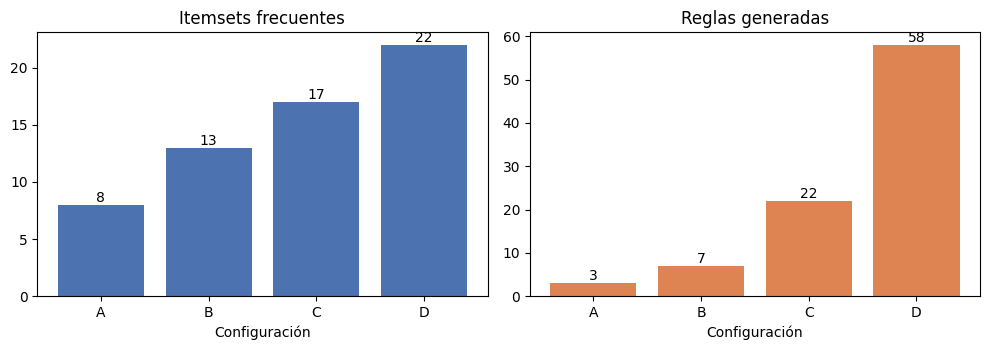

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
etiquetas = [c["config"].split(" ·")[0] for c in CONFIGS]

axes[0].bar(etiquetas, tabla_comparativa["Itemsets frecuentes"], color="#4C72B0")
axes[0].set_title("Itemsets frecuentes")
axes[1].bar(etiquetas, tabla_comparativa["Reglas"], color="#DD8452")
axes[1].set_title("Reglas generadas")
for ax in axes:
    ax.set_xlabel("Configuración")
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.show()

### Conclusión del experimento

| Config. | Soporte / Confianza | Itemsets | Reglas | Lift máx. |
|---|---|---|---|---|
| A | 0.25 / 0.50 | 8 | 3 | 1.01 |
| B | 0.15 / 0.40 | 13 | 7 | 1.01 |
| C | 0.10 / 0.30 | 17 | 22 | 1.21 |
| D | 0.05 / 0.10 | 22 | 58 | 1.21 |

1. **Las configuraciones estrictas (A y B) no encuentran ninguna asociación real.** Su lift máximo es 1.01, es decir, los productos se compran casi como si fueran independientes. Solo sobreviven pares que incluyen pan, porque el pan es el producto más común (55 % de las compras).
2. **El soporte mínimo controla cuántos itemsets existen** (de 8 a 22 al bajar de 0.25 a 0.05, sobre un máximo de 31 posibles). En un catálogo grande este crecimiento sería explosivo y es lo que agota la memoria.
3. **La confianza mínima controla cuántas reglas salen de esos itemsets:** de 22 (C) a 58 (D). Pero el lift máximo no sube (1.21 en ambas) y el lift mínimo cae a 0.44: las reglas añadidas en D no traen asociaciones más fuertes. Aparecen por apoyarse en una sola compra o por tener confianzas bajo 0.30.
4. **Más reglas no significa mejores reglas.** Elijo la configuración **C (0.10 / 0.30)**: es la más estricta que todavía deja ver las únicas dos combinaciones de productos con lift sobre 1.1 (pan con huevos y leche, y pan con mantequilla y jugo), y exige al menos 2 compras de respaldo.
5. **Advertencia:** con 20 compras, el 0.10 equivale a solo 2 compras. Las conclusiones de negocio de la Fase 5 son indicios que habría que confirmar con más datos.

### Verificación manual de una regla

Cuento directamente sobre las transacciones la regla con mejor lift, sin `mlxtend`, como en la Actividad 2.5.

In [17]:
transacciones = df.groupby("id_transaccion")["item"].apply(set).tolist()

regla_top = reglas.iloc[0]
A = set(regla_top["antecedents"])
B = set(regla_top["consequents"])

n_A = sum(1 for t in transacciones if A <= t)
n_AB = sum(1 for t in transacciones if (A | B) <= t)
n_B = sum(1 for t in transacciones if B <= t)

soporte_manual = n_AB / len(transacciones)
confianza_manual = n_AB / n_A
lift_manual = confianza_manual / (n_B / len(transacciones))

print(f"Regla: {regla_top['antecedente']}  →  {regla_top['consecuente']}\n")
print(f"Compras con el antecedente             : {n_A}")
print(f"Compras con antecedente y consecuente  : {n_AB}")
print(f"Compras con el consecuente             : {n_B}\n")

comparacion = pd.DataFrame({
    "Métrica": ["Soporte", "Confianza", "Lift"],
    "Conteo manual": [soporte_manual, confianza_manual, lift_manual],
    "mlxtend": [regla_top["support"], regla_top["confidence"], regla_top["lift"]],
})
comparacion["¿Coincide?"] = np.isclose(comparacion["Conteo manual"], comparacion["mlxtend"])
comparacion

Regla: butter + juice  →  bread

Compras con el antecedente             : 3
Compras con antecedente y consecuente  : 2
Compras con el consecuente             : 11



,Métrica,Conteo manual,mlxtend,¿Coincide?
0,Soporte,0.100000,0.100000,True
1,Confianza,0.666667,0.666667,True
2,Lift,1.212121,1.212121,True


In [18]:
for t_id, t in df.groupby("id_transaccion")["item"].apply(set).items():
    if A <= t:
        marca = "✔ también tiene el consecuente" if B <= t else "✘ no lo tiene"
        print(f"Compra {t_id}: {sorted(t)}  ->  {marca}")

Compra 2: ['bread', 'butter', 'juice']  ->  ✔ también tiene el consecuente
Compra 6: ['butter', 'juice']  ->  ✘ no lo tiene
Compra 15: ['bread', 'butter', 'juice']  ->  ✔ también tiene el consecuente


## Fase 5 · Interpretación en lenguaje de negocio

### Las cinco reglas más valiosas

Criterios (sobre la configuración base C):

- **Lift > 1**, para que la asociación no sea un efecto de productos populares.
- **Al menos 2 compras de respaldo.**
- **Una regla por combinación de productos** (A→B y B→A son la misma pareja; se conserva la de mejor lift).

In [19]:
MIN_CASOS = 2

ES = {"bread": "pan", "milk": "leche", "eggs": "huevos", "juice": "jugo", "butter": "mantequilla"}


def es(nombres):
    return " y ".join(ES.get(n, n) for n in sorted(nombres))


def en_negocio(r):
    ant = es(r["antecedents"])
    con = es(r["consequents"])
    return (f"De cada 100 compras que incluyen {ant}, {r['confidence'] * 100:.0f} también llevan {con} "
            f"({r['compras']} de {r['compras_antecedente']} compras), frente a "
            f"{r['consequent support'] * 100:.0f} de cada 100 compras en general.")


candidatas = reglas[(reglas["lift"] > 1.0000001) & (reglas["compras"] >= MIN_CASOS)].copy()
candidatas["pareja"] = candidatas.apply(lambda r: frozenset(r["antecedents"] | r["consequents"]), axis=1)
candidatas = candidatas.drop_duplicates("pareja")
top5 = candidatas.head(5).reset_index(drop=True)

print(f"Reglas con lift > 1 y al menos {MIN_CASOS} compras: {len(candidatas)}\n")
for i, r in top5.iterrows():
    print(f"{i + 1}. {en_negocio(r)}  [lift {r['lift']:.2f}]")

top5[COLS_VISTA].round(3)

Reglas con lift > 1 y al menos 2 compras: 5

1. De cada 100 compras que incluyen mantequilla y jugo, 67 también llevan pan (2 de 3 compras), frente a 55 de cada 100 compras en general.  [lift 1.21]
2. De cada 100 compras que incluyen huevos y leche, 67 también llevan pan (2 de 3 compras), frente a 55 de cada 100 compras en general.  [lift 1.21]
3. De cada 100 compras que incluyen huevos, 56 también llevan pan (5 de 9 compras), frente a 55 de cada 100 compras en general.  [lift 1.01]
4. De cada 100 compras que incluyen jugo, 56 también llevan pan (5 de 9 compras), frente a 55 de cada 100 compras en general.  [lift 1.01]
5. De cada 100 compras que incluyen leche, 56 también llevan pan (5 de 9 compras), frente a 55 de cada 100 compras en general.  [lift 1.01]


,antecedente,consecuente,compras,support,confidence,lift
0,butter + juice,bread,2,0.10,0.667,1.212
1,eggs + milk,bread,2,0.10,0.667,1.212
2,eggs,bread,5,0.25,0.556,1.010
3,juice,bread,5,0.25,0.556,1.010
4,milk,bread,5,0.25,0.556,1.010


**Lectura honesta de las cinco:** solo las dos primeras (lift 1.21) muestran una asociación apreciable, y cada una se apoya en **2 compras**. Las otras tres (pan con leche, jugo o huevos) tienen lift 1.01, es decir, son prácticamente independientes: se listan porque el enunciado pide cinco, pero su valor de negocio es mínimo.

### Una regla que descartaría aunque supera los umbrales

Entre las reglas que pasan los umbrales con lift menor a 1, tomo la de **mayor confianza**: se ve atractiva en una tabla ordenada por confianza, pero es engañosa.

In [20]:
descartada = reglas[reglas["lift"] < 0.9999999].sort_values("confidence", ascending=False).iloc[0]

ant_d, con_d = es(descartada["antecedents"]), es(descartada["consequents"])

print(f"REGLA DESCARTADA: {descartada['antecedente']}  →  {descartada['consecuente']}  ({ant_d} → {con_d})\n")
print(f"  Compras de respaldo        : {descartada['compras']} de {descartada['compras_antecedente']} con el antecedente")
print(f"  Soporte                    : {descartada['support']:.2f}")
print(f"  Confianza                  : {descartada['confidence']:.2f}")
print(f"  Soporte del consecuente    : {descartada['consequent support']:.2f}")
print(f"  Lift                       : {descartada['lift']:.2f}\n")
print("Justificación:")
print(f"  - Pasa los umbrales (soporte >= {SOP_BASE} y confianza >= {CONF_BASE}), por eso aparece en la tabla.")
print(f"  - {con_d.capitalize()} está en el {descartada['consequent support'] * 100:.0f}% de todas las compras, "
      f"pero solo en el {descartada['confidence'] * 100:.0f}% de las que incluyen {ant_d}.")
print(f"  - Con lift = {descartada['lift']:.2f} (< 1), quienes llevan {ant_d} compran {con_d} menos seguido que el cliente promedio.")
print("  - Armar una promoción o un combo con estos dos productos iría contra el comportamiento real de los clientes.")

REGLA DESCARTADA: butter  →  bread  (mantequilla → pan)

  Compras de respaldo        : 4 de 8 con el antecedente
  Soporte                    : 0.20
  Confianza                  : 0.50
  Soporte del consecuente    : 0.55
  Lift                       : 0.91

Justificación:
  - Pasa los umbrales (soporte >= 0.1 y confianza >= 0.3), por eso aparece en la tabla.
  - Pan está en el 55% de todas las compras, pero solo en el 50% de las que incluyen mantequilla.
  - Con lift = 0.91 (< 1), quienes llevan mantequilla compran pan menos seguido que el cliente promedio.
  - Armar una promoción o un combo con estos dos productos iría contra el comportamiento real de los clientes.


### Decisión concreta para un administrador

In [21]:
r1 = top5.iloc[0]
a1 = es(r1["antecedents"])
c1 = es(r1["consequents"])

mantequilla = reglas[(reglas["consecuente"] == "butter") & ~reglas["antecedente"].str.contains(r"\+")]

lineas = [
    "DECISIÓN PROPUESTA",
    "------------------",
    f"Acción   : ofrecer un pack «{a1}» con descuento en {c1}, y ubicar {c1} cerca de {a1}.",
    f"Por qué  : {en_negocio(r1)}",
    f"Evidencia: {r1['compras']} compras. Es una señal débil, por eso se plantea como piloto y no como cambio definitivo.",
    f"Medición : 4 semanas de piloto comparando las ventas de {c1} en compras con {a1} contra las 4 semanas previas.",
    f"Éxito    : aumento sostenido de las compras conjuntas sin bajar la venta individual de cada producto.",
    f"Evitar   : promociones que intenten vender mantequilla a quien ya lleva otro producto; en {(mantequilla['lift'] < 1).sum()} de {len(mantequilla)} reglas de un producto hacia mantequilla el lift es menor a 1 "
    f"(máximo {mantequilla['lift'].max():.2f}).",
]
print("\n".join(lineas))

DECISIÓN PROPUESTA
------------------
Acción   : ofrecer un pack «mantequilla y jugo» con descuento en pan, y ubicar pan cerca de mantequilla y jugo.
Por qué  : De cada 100 compras que incluyen mantequilla y jugo, 67 también llevan pan (2 de 3 compras), frente a 55 de cada 100 compras en general.
Evidencia: 2 compras. Es una señal débil, por eso se plantea como piloto y no como cambio definitivo.
Medición : 4 semanas de piloto comparando las ventas de pan en compras con mantequilla y jugo contra las 4 semanas previas.
Éxito    : aumento sostenido de las compras conjuntas sin bajar la venta individual de cada producto.
Evitar   : promociones que intenten vender mantequilla a quien ya lleva otro producto; en 4 de 4 reglas de un producto hacia mantequilla el lift es menor a 1 (máximo 0.91).


### Reflexión final

Lo más difícil fue elegir los umbrales con solo 20 compras: con soporte 0.05 una sola compra ya cuenta como patrón, y con umbrales altos no aparece ninguna asociación real. Aprendí que la confianza sola engaña, porque el pan está en el 55 % de las compras y casi cualquier regla que lo tenga como consecuente parece fuerte, y que el lift separa lo real de lo aparente. La verificación manual de una regla me confirmó que la codificación one-hot quedó bien hecha. Las reglas encontradas son indicios débiles: las mejores se apoyan en 2 compras y habría que probarlas con más datos o con un piloto en tienda. Lo que aquí aprendí sobre umbrales y lift lo usaré en el proyecto final.